In [1]:
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))

from common import contract, data, metrics, paths, plots, verify

import rf

RAIZ = paths.ROOT               # os notebooks moram em utils/
PROCESSADO = paths.SPLITS

LIB = paths.LIB_RF
SRC = paths.LIB_RF_SRC

SCRATCH = paths.SCRATCH

SEMENTE = contract.SEED
ALVO = contract.TARGET
FEATURES = contract.RF_FEATURES
GRANULARIDADES = contract.GRANULARIDADES          # ("5min", "10min", "1h", "1D")
ROTULO = contract.GRANULARIDADE_LABEL

# O treino so' gera os joblibs em dist/. A biblioteca C do firmware sai pelo
# SCRIPT SEPARADO utils/gerar_lib_rf.py, que carrega o joblib da granularidade
# embarcada (o firmware leva uma lib por vez).

PCA_MIN, PCA_MAX = data.physical_target_limits()

np.random.seed(SEMENTE)

print("features:", ", ".join(FEATURES))
print("splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)")
print(f"granularidades do treino: {', '.join(ROTULO[f] for f in GRANULARIDADES)}")
print("lib C: gerada pelo script utils/gerar_lib_rf.py a partir dos joblibs")
print("g++ host:", subprocess.run([verify.GXX, "--version"], capture_output=True,
                                 text=True).stdout.splitlines()[0])
print("xtensa  :", "ok" if verify.XTENSA_GXX.exists() else "AUSENTE")
print("entrega :", LIB.relative_to(RAIZ))


features: temp_amb, ghit, jacques
splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)
granularidades do treino: 5 min, 10 min, 1 h, 1 d
lib C: gerada pelo script utils/gerar_lib_rf.py a partir dos joblibs
g++ host: g++.EXE (x86_64-posix-seh-rev0, Built by MinGW-Builds project) 16.1.0
xtensa  : ok
entrega : lib\knob-senses-rf


In [2]:
# Um dicionario por granularidade, como no treino_mlp: splits, z-score com
# constantes SO do treino e o BRUTO do teste (para o conferidor da lib).
dados = {}
for freq in GRANULARIDADES:
    treino = data.load_split("train", freq=freq)
    calibracao = data.load_split("calibration", freq=freq)
    teste = data.load_split("test", freq=freq)

    # Sanidade: o csv precisa estar em GRANDEZA FISICA. Se alguem voltar a
    # normalizar no prep, estes limites quebram AQUI, e nao em campo, com o
    # firmware normalizando duas vezes e a previsao colapsando num valor fixo.
    for nome, d in (("train", treino), ("calibration", calibracao), ("test", teste)):
        data.check_physical_scale(f"{freq}/{nome}", d)

    MEDIA, DESVIO = data.fit_normalization(treino)
    dados[freq] = dict(
        treino=treino, calibracao=calibracao, teste=teste,
        media=MEDIA, desvio=DESVIO,
        X_tre=data.z_score(treino, MEDIA, DESVIO).to_numpy(np.float32),
        y_tre=treino[ALVO].to_numpy(np.float32),
        X_cal=data.z_score(calibracao, MEDIA, DESVIO).to_numpy(np.float32),
        y_cal=calibracao[ALVO].to_numpy(np.float32),
        X_tes=data.z_score(teste, MEDIA, DESVIO).to_numpy(np.float32),
        y_tes=teste[ALVO].to_numpy(np.float32),
        bruto_tes=teste[list(FEATURES)].to_numpy(np.float32),
    )
    print(f"{ROTULO[freq]:>6} | treino {len(dados[freq]['y_tre']):6} "
          f"| calibracao {len(dados[freq]['y_cal']):5} "
          f"| teste {len(dados[freq]['y_tes']):5} "
          f"| PCA {dados[freq]['y_tre'].min():.3f}..{dados[freq]['y_tre'].max():.2f} kW")

print("OK: os csv estao em grandeza fisica (brutos); z-score ajustado so no treino")


 5 min | treino 156440 | calibracao 22533 | teste 44911 | PCA 0.000..1.99 kW
10 min | treino  79065 | calibracao 11366 | teste 22637 | PCA 0.000..1.99 kW
   1 h | treino  14133 | calibracao  2033 | teste  4042 | PCA 0.000..1.97 kW
   1 d | treino   1250 | calibracao   182 | teste   354 | PCA 0.000..1.32 kW
OK: os csv estao em grandeza fisica (brutos); z-score ajustado so no treino


In [3]:
from common.metrics import evaluate

resultados = {}      # resultados[freq] = lista de metricas por modelo


In [4]:
from sklearn.linear_model import LinearRegression

# Linha de base de referencia: regressao linear multipla nas mesmas features.
# Treino imediato e um acerto que qualquer modelo nao-linear precisa superar
# para justificar a complexidade.
for freq in GRANULARIDADES:
    d = dados[freq]
    lin = LinearRegression().fit(d["X_tre"], d["y_tre"])
    pred = lin.predict(d["X_tes"]).ravel()
    print(freq, end='\t')
    resultados[freq] = [evaluate(f"regressao linear", d["y_tes"], pred)]

print("baseline ajustada nas quatro granularidades")


5min	regressao linear     MAE 0.1999 kW | RMSE 0.2775 kW | R2 0.7426 | vies +0.1059 kW
10min	regressao linear     MAE 0.1561 kW | RMSE 0.2071 kW | R2 0.8457 | vies +0.1130 kW
1h	regressao linear     MAE 0.1168 kW | RMSE 0.1531 kW | R2 0.9048 | vies +0.1140 kW
1D	regressao linear     MAE 0.1199 kW | RMSE 0.1325 kW | R2 0.5338 | vies +0.1199 kW
baseline ajustada nas quatro granularidades


In [5]:
import joblib
from sklearn.ensemble import RandomForestRegressor

paths.DIST.mkdir(parents=True, exist_ok=True)

# Varredura + treino final, por granularidade, numa execucao so. O vencedor
# sai do R2 JA CALIBRADO (offset do proprio candidato) na calibracao; as
# colunas de teste sao report-only. O modelo final e' salvo em dist/ ANTES de
# qualquer compilacao: a cruzada e a etapa da lib carregam o joblib.
for freq in GRANULARIDADES:
    d = dados[freq]
    print(f"===== {ROTULO[freq]} =====")
    print(f"{'config':>22} {'nos':>8} {'prof':>5} {'KB (est.)':>10} {'MAE':>8} {'R2':>8} "
          f"{'offset':>8} {'MAE cal':>8} {'R2 cal':>8} {'MAE teste':>10} {'R2 teste':>9} "
          f"{'s':>5} {'s_inf (us)':>10}")
    print("-" * 133)

    varredura = rf.sweep(d["X_tre"], d["y_tre"], d["X_cal"], d["y_cal"],
                         d["X_tes"], d["y_tes"])
    for r_ in varredura.itertuples():
        prof = "-" if pd.isna(r_.prof_max) else f"{int(r_.prof_max)}"
        print(f"{f'{r_.arvores}arv folha={r_.folha} d={prof}':>22} {r_.nos:8} {r_.prof:5} "
              f"{r_.kb:10.1f} {r_.mae:8.4f} {r_.r2:8.4f} {r_.offset:+8.4f} "
              f"{r_.mae_cal:8.4f} {r_.r2_cal:8.4f} {r_.mae_tes:10.4f} {r_.r2_tes:9.4f} "
              f"{r_.s:5.1f} {r_.s_inf * 1e6:10.1f}")

    top2 = varredura.nlargest(2, "r2_cal")
    # Desempate pelo MENOR tempo de inferencia por amostra (s_inf, medido na
    # calibracao); se a medicao faltar, cai para a menor quantidade de nos.
    if top2["s_inf"].notna().all():
        melhor = top2.loc[top2.s_inf.idxmin()]
    else:
        melhor = top2.loc[top2.nos.idxmin()]
    print(f"melhor na calibracao (entre os 2 maiores R2 calibrado, menor tempo de "
          f"inferencia): {int(melhor.arvores)} arvores, folha={int(melhor.folha)} "
          f"(R2 cal={melhor.r2_cal:.4f}, MAE cal={melhor.mae_cal:.4f}, "
          f"s_inf={melhor.s_inf * 1e6:.1f} us/amostra) com {melhor.kb:.0f} KB estimados")

    t0 = time.perf_counter()
    modelo = RandomForestRegressor(
        n_jobs=-1,
        n_estimators=int(melhor.arvores),
        min_samples_leaf=int(melhor.folha),
        # O vencedor da varredura pode ter teto de profundidade (max_depth): o
        # modelo final tem que ser O MESMO que a varredura avaliou.
        max_depth=None if pd.isna(melhor.prof_max) else int(melhor.prof_max),
        random_state=contract.SEED,
    ).fit(d["X_tre"], d["y_tre"])
    print(f"treino: {time.perf_counter() - t0:.1f} s")

    # Calibracao do vies: offset = media(real - previsto) na calibracao (2024H2).
    # O modelo foi treinado ate' 2024H1; 2024H2 ja' mostra a queda de eficiencia.
    pred_cal = modelo.predict(d["X_cal"])
    offset = float(np.mean(d["y_cal"] - pred_cal))

    pred_rf = modelo.predict(d["X_tes"]) + offset
    d["pred_tes"] = pred_rf
    resultados[freq].append(evaluate("random forest", d["y_tes"], pred_rf))
    print(f"offset de calibracao (2024H2): {offset:+.4f} kW")

    n_nos = rf.count_nodes(modelo)
    print(f"{n_nos} nos em {modelo.n_estimators} arvores "
          f"({n_nos // modelo.n_estimators} por arvore, profundidade maxima "
          f"{rf.tree_depth(modelo)})")

    importancia = pd.Series(modelo.feature_importances_, index=FEATURES).sort_values()
    print("importancia:", importancia.round(4).to_dict())

    # Salva ANTES de compilar: o .joblib guarda o estimador e as constantes
    # necessarias para reproduzir a previsao em Python (e para a cruzada).
    caminho_modelo = paths.DIST / f"random_forest_{freq}.joblib"
    joblib.dump({
        "modelo": modelo,
        "freq": freq,
        "features": list(FEATURES),
        "media": d["media"].to_dict(),
        "desvio": d["desvio"].to_dict(),
        "offset_calibracao_kw": offset,
        "pca_min_kw": float(PCA_MIN),
        "pca_max_kw": float(PCA_MAX),
        "metricas": resultados[freq][1],
    }, caminho_modelo)
    print(f"modelo salvo: {caminho_modelo.relative_to(RAIZ)} "
          f"({caminho_modelo.stat().st_size / 1024:.1f} KB)")


===== 5 min =====
                config      nos  prof  KB (est.)      MAE       R2   offset  MAE cal   R2 cal  MAE teste  R2 teste     s s_inf (us)
-------------------------------------------------------------------------------------------------------------------------------------
    300arv folha=2 d=- 25828810    76   353128.8   0.2098   0.7243  -0.0774   0.1968   0.7438     0.1764    0.7837  48.3       81.7
    100arv folha=2 d=-  8608964    68   117700.9   0.2102   0.7236  -0.0773   0.1973   0.7430     0.1768    0.7830  16.1        8.7
     50arv folha=5 d=-  1597400    54    21839.6   0.2059   0.7326  -0.0779   0.1926   0.7523     0.1724    0.7911   6.3        4.5
     50arv folha=5 d=8    23988     8      328.1   0.1982   0.7484  -0.0798   0.1829   0.7691     0.1638    0.8051   3.1        2.5
    50arv folha=20 d=-   384880    38     5262.1   0.2009   0.7433  -0.0778   0.1867   0.7630     0.1671    0.8000   5.0        3.0
    30arv folha=50 d=-    91770    29     1254.7   0.199

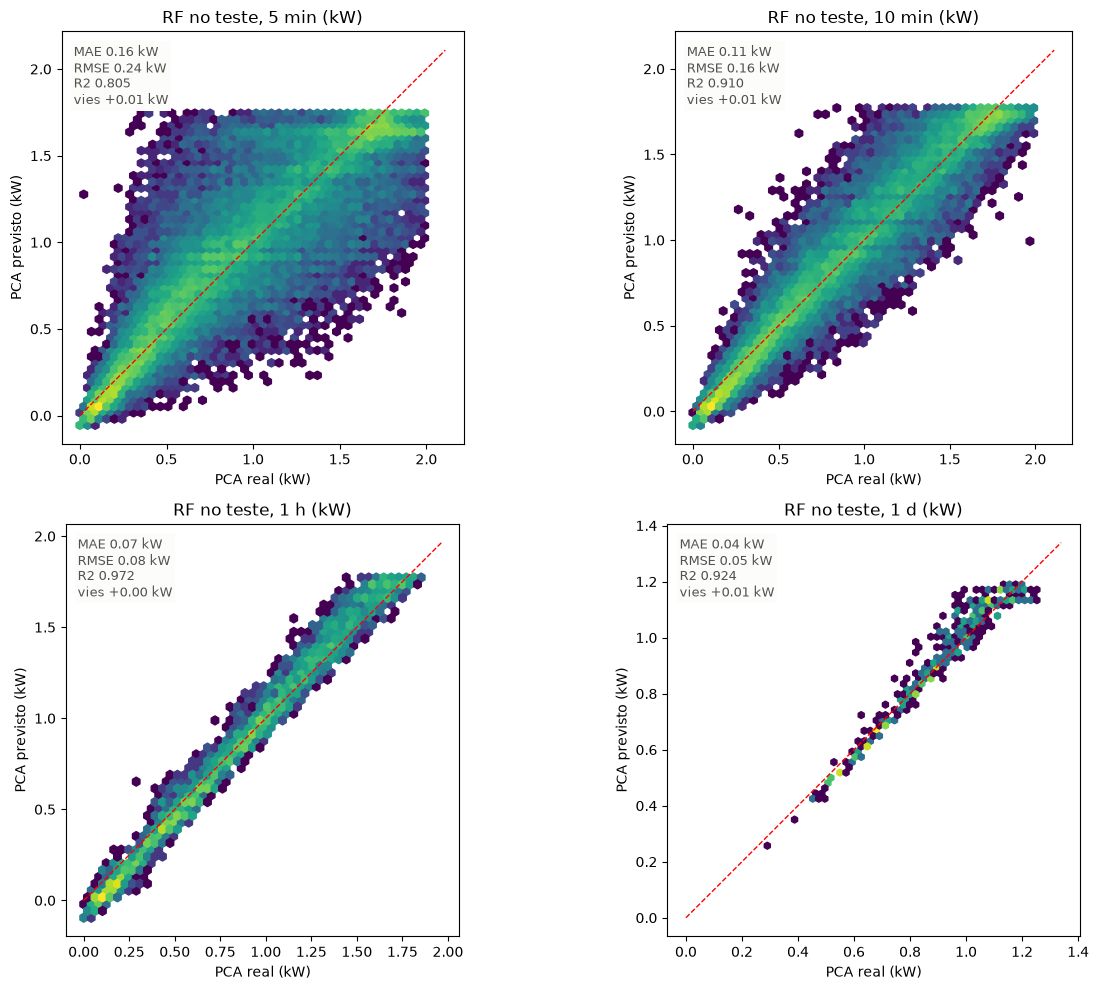

In [6]:
# Hexbins de real x predito por granularidade (mesmo formato da figura do
# MLP na monografia).
fig, eixos = plt.subplots(2, 2, figsize=(13, 10))
for eixo, freq in zip(eixos.ravel(), GRANULARIDADES):
    d = dados[freq]
    r = resultados[freq][1]
    plots.hexbin_real_vs_pred(eixo, d["y_tes"], d["pred_tes"],
                              f"RF no teste, {ROTULO[freq]} (kW)")
    texto = chr(10).join([
        f"MAE {r['MAE (kW)']:.2f} kW",
        f"RMSE {r['RMSE (kW)']:.2f} kW",
        f"R2 {r['R2']:.3f}",
        f"vies {r['vies (kW)']:+.2f} kW",
    ])
    eixo.text(0.03, 0.97, texto, transform=eixo.transAxes, va="top",
              color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plt.show()
fig.savefig(paths.ROOT / 'docs' / 'figuras' / 'rf_avaliacao_granularidades.png',
            dpi=200, bbox_inches='tight')


A=5min em B=5min     MAE 0.1637 kW | RMSE 0.2414 kW | R2 0.8052 | vies +0.0130 kW
A=5min em B=10min    MAE 0.1168 kW | RMSE 0.1597 kW | R2 0.9083 | vies +0.0197 kW
A=5min em B=1h       MAE 0.0709 kW | RMSE 0.0929 kW | R2 0.9649 | vies +0.0314 kW
A=5min em B=1D       MAE 0.0859 kW | RMSE 0.1066 kW | R2 0.6982 | vies +0.0809 kW
A=10min em B=5min    MAE 0.1638 kW | RMSE 0.2483 kW | R2 0.7940 | vies -0.0006 kW
A=10min em B=10min   MAE 0.1142 kW | RMSE 0.1582 kW | R2 0.9100 | vies +0.0062 kW
A=10min em B=1h      MAE 0.0631 kW | RMSE 0.0813 kW | R2 0.9731 | vies +0.0155 kW
A=10min em B=1D      MAE 0.0672 kW | RMSE 0.0858 kW | R2 0.8046 | vies +0.0570 kW
A=1h em B=5min       MAE 0.1705 kW | RMSE 0.2581 kW | R2 0.7774 | vies -0.0120 kW
A=1h em B=10min      MAE 0.1197 kW | RMSE 0.1643 kW | R2 0.9029 | vies -0.0053 kW
A=1h em B=1h         MAE 0.0664 kW | RMSE 0.0835 kW | R2 0.9717 | vies +0.0024 kW
A=1h em B=1D         MAE 0.0560 kW | RMSE 0.0724 kW | R2 0.8609 | vies +0.0404 kW
A=1D em B=5min  

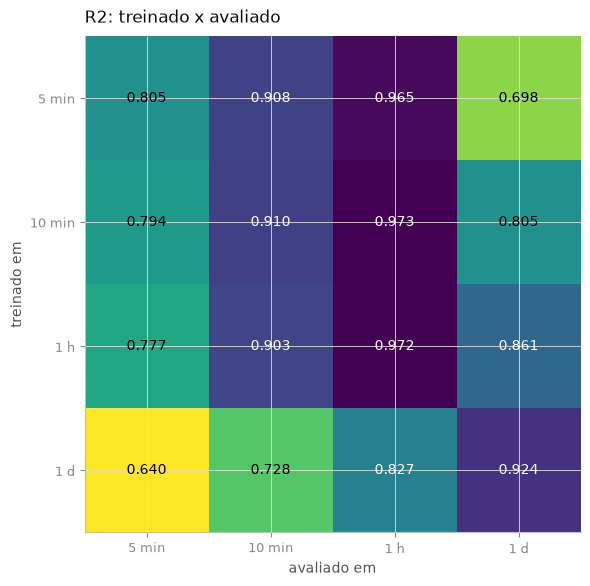

In [7]:
import joblib

# Analise cruzada de granularidades: cada modelo treinado avalia no teste das
# QUATRO granularidades, carregado do joblib salvo (o mesmo artefato que a
# etapa da lib usa). O teste de B e' reescalado com o z-score do treino de A
# (fora da faixa usual quando B e' mais fino que A: o modelo extrapola, e e'
# exatamente isso que a analise mede). A comparacao e' pelo R2. A diagonal e'
# o proprio modelo; abaixo dela, modelo grosso avaliado em dado fino.
modelos = {freq: joblib.load(paths.DIST / f"random_forest_{freq}.joblib")
           for freq in GRANULARIDADES}

cruzada = []
for freq_a in GRANULARIDADES:
    pkg_a = modelos[freq_a]
    media_a = pd.Series(pkg_a["media"])
    desvio_a = pd.Series(pkg_a["desvio"])
    linha = {"treinado": ROTULO[freq_a]}
    for freq_b in GRANULARIDADES:
        dB = dados[freq_b]
        X_b = data.z_score(dB["teste"], media_a, desvio_a).to_numpy(np.float32)
        pred = pkg_a["modelo"].predict(X_b) + pkg_a["offset_calibracao_kw"]
        r = evaluate(f"A={freq_a} em B={freq_b}", dB["y_tes"], pred)
        linha[ROTULO[freq_b]] = r["R2"]
    cruzada.append(linha)

tabela_cruzada = pd.DataFrame(cruzada)
colunas = ["treinado", *[ROTULO[f] for f in GRANULARIDADES]]
print("R2 por par treinado x avaliado:")
print(tabela_cruzada[colunas].round(4).to_string(index=False))

fig, eixo = plt.subplots(figsize=(7, 5.5))
m = tabela_cruzada.set_index("treinado")[[ROTULO[f] for f in GRANULARIDADES]]
eixo.imshow(m.to_numpy(), cmap="viridis_r")
eixo.set_xticks(range(len(GRANULARIDADES)), [ROTULO[f] for f in GRANULARIDADES])
eixo.set_yticks(range(len(GRANULARIDADES)), m.index)
meio = (m.to_numpy().min() + m.to_numpy().max()) / 2
for i in range(len(m)):
    for j in range(len(m.columns)):
        eixo.text(j, i, f"{m.iloc[i, j]:.3f}", ha="center", va="center",
                  color="white" if m.iloc[i, j] > meio else "black")
fig.tight_layout()
fig.savefig(paths.ROOT / "docs" / "figuras" / "rf_cruzada.png",
            dpi=200, bbox_inches="tight")
plots.enfeitar(eixo, "R2: treinado x avaliado",
               "avaliado em", "treinado em")
plt.show()


In [8]:
print(f"{'modelo':>26} {'granularidade':>14} {'MAE':>9} {'RMSE':>9} {'R2':>9} {'MAE c/ clip':>12} {'vies':>9}")
print("-" * 96)
for freq in GRANULARIDADES:
    for r_ in resultados[freq]:
        print(f"{r_['modelo']:>26} {ROTULO[freq]:>14} {r_['MAE (kW)']:9.4f} "
              f"{r_['RMSE (kW)']:9.4f} {r_['R2']:9.4f} "
              f"{r_['MAE com clip (kW)']:12.4f} {r_['vies (kW)']:+9.4f}")


                    modelo  granularidade       MAE      RMSE        R2  MAE c/ clip      vies
------------------------------------------------------------------------------------------------
          regressao linear          5 min    0.1999    0.2775    0.7426       0.1958   +0.1059
             random forest          5 min    0.1637    0.2414    0.8052       0.1635   +0.0130
          regressao linear         10 min    0.1561    0.2071    0.8457       0.1508   +0.1130
             random forest         10 min    0.1142    0.1582    0.9100       0.1137   +0.0062
          regressao linear            1 h    0.1168    0.1531    0.9048       0.1147   +0.1140
             random forest            1 h    0.0664    0.0835    0.9717       0.0657   +0.0024
          regressao linear            1 d    0.1199    0.1325    0.5338       0.1199   +0.1199
             random forest            1 d    0.0396    0.0535    0.9240       0.0396   +0.0130


### Etapa da lib (script separado)

A biblioteca C do firmware nao sai mais deste notebook: o script
`utils/gerar_lib_rf.py` carrega o joblib salvo e gera a lib do PlatformIO.

```
python utils/gerar_lib_rf.py 1h           # gera a lib da granularidade 1h
python utils/gerar_lib_rf.py 1h --medir   # gera e mede flash/RAM (xtensa)
```

O firmware embarca uma lib por vez; escolha a `freq` do ensaio.
